# Краткий EDA: почасовая цена aFRR UP в Венгрии

**2023–2025 годы · основной EDA · данные из PostgreSQL**

Я исследовал качество данных, поведение цены и простые связи между показателями.
В этом ноутбуке я оставил только базовый разведочный анализ.

Я прочитал данные из таблицы `public.afrr_prices` в PostgreSQL за период
с 1 января 2023 года включительно до 1 января 2026 года, не включая эту границу.
Значения показателей я не менял. Я привёл даты к UTC, проверил данные и построил графики.
Запрос работает только на чтение.

**Как запустить.** Ячейки выполняются сверху вниз. Параметры подключения находятся
в локальном файле `.env`, пароль в ноутбуке не хранится.
Я разместил ноутбук в `notebooks/eda.ipynb`. Локальный `.env` нужно положить
в корень репозитория, на уровень выше `notebooks/`, или рядом с ноутбуком.
Код поддерживает запуск из корня репозитория и из папки `notebooks/`. В `.env` нужны `DB_HOST`, `DB_PORT`, `DB_NAME`,
`DB_USER` и `DB_PASSWORD`. Пароль нельзя добавлять в публикуемую копию проекта.
Если поле пароля оставлено пустым, при запуске появится скрытый запрос ввода.

Я использовал `pandas`, `matplotlib`, `seaborn`, `SQLAlchemy`, `psycopg`
и `python-dotenv`. Основные зависимости устанавливаются по инструкции проекта.
Если появляется `ModuleNotFoundError: No module named 'dotenv'`, дополнительную
зависимость можно установить в отдельной временной ячейке:

```python
%pip install python-dotenv
```

После установки нужно перезапустить ядро и выполнить ноутбук сверху вниз.
В рабочих ячейках автоматической установки нет.

**Сохранённые результаты относятся к времени загрузки, указанному под SQL-запросом.**
Повторный запуск обновляет таблицы, графики и численные результаты из базы.
Для обновления нужны доступ к серверу и правильные реквизиты; для просмотра уже сохранённых
результатов подключение не требуется.

## 1. Какие данные я исследовал

В таблице одна строка соответствует одному часу. Целевая переменная — `target_vwap_up`.
Остальные числовые показатели по исходному описанию относятся к прогнозам на час поставки.
В этой таблице нет времени публикации этих прогнозов.

| Столбец | Что означает | Единица по описанию |
|---|---|---|
| `datetime` | Дата и час поставки | UTC |
| `target_vwap_up` | Предоставленный показатель цены aFRR UP | €/МВт·ч |
| `consumption` | Потребление | МВт·ч/ч |
| `wind` | Ветровая генерация | МВт·ч/ч |
| `solar` | Солнечная генерация | МВт·ч/ч |
| `nuclear` | Генерация АЭС | МВт·ч/ч |
| `temperature` | Температура | °C |
| `exchange_net_export` | Чистый экспорт | МВт·ч/ч |
| `carbon_intensity_production` | Углеродоёмкость генерации | кг CO₂-экв./МВт·ч |

МВт·ч/ч соответствует средней мощности в МВт за час. Знак перетоков я трактую
согласно названию столбца; точное соглашение о знаке нужно подтвердить у источника.
Точный экономический смысл целевой цены также требует описания источника.

In [1]:
# Библиотеки для таблиц, графиков и подключения к PostgreSQL.
from pathlib import Path
from getpass import getpass
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import dotenv_values
from sqlalchemy import URL, create_engine, text

sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams["figure.figsize"] = (11, 4)
pd.options.display.float_format = "{:,.2f}".format

### Подключение и запрос

Я читаю реквизиты из `.env`. `URL.create` собирает адрес подключения и корректно
обрабатывает специальные символы в пароле. Значения реквизитов я не вывожу на экран.
`sslmode="require"` включает шифрование соединения, а `default_transaction_read_only=on`
задаёт режим чтения. Таймауты ограничивают ожидание подключения и выполнения запроса.

In [2]:
env_path = Path(".env")
if not env_path.is_file():
    env_path = Path("../.env")
if not env_path.is_file():
    raise FileNotFoundError("Нужен локальный .env в корне репозитория или рядом с ноутбуком.")
settings = dotenv_values(env_path, interpolate=False)
password = settings.get("DB_PASSWORD") or getpass("Пароль PostgreSQL: ")
url = URL.create("postgresql+psycopg", host=settings["DB_HOST"],
    port=int(settings.get("DB_PORT", 5432)), database=settings["DB_NAME"],
    username=settings["DB_USER"], password=password)
engine = create_engine(url, connect_args={"sslmode": "require", "connect_timeout": 10,
    "options": "-c default_transaction_read_only=on -c statement_timeout=30000 -c timezone=UTC"})

В серверной таблице дата хранится как текст с явным смещением `+00:00`.
Я проверил этот формат. В SQL запись `::timestamptz` переводит текст в дату с часовым поясом.
`SELECT` выбирает нужные столбцы, `WHERE` ограничивает период, `ORDER BY` упорядочивает часы.
Границы периода передаются отдельно через параметры `:start` и `:end`.

In [3]:
period = {"start": "2023-01-01 00:00:00+00:00", "end": "2026-01-01 00:00:00+00:00"}
query = text("""
SELECT datetime::timestamptz AS datetime,
       consumption, wind, solar, nuclear, temperature,
       exchange_net_export, carbon_intensity_production, target_vwap_up
FROM public.afrr_prices
WHERE datetime::timestamptz >= CAST(:start AS timestamptz)
  AND datetime::timestamptz < CAST(:end AS timestamptz)
ORDER BY datetime::timestamptz
""")

`read_sql_query` возвращает результат запроса как обычную таблицу pandas.
Для углеродоёмкости я явно задал числовой тип: это позволяет корректно представить
полностью пустой SQL-столбец как пропуски, сохранив его в анализе.
После загрузки я закрываю соединение; остальные расчёты выполняются в памяти ноутбука.

In [4]:
try:
    with engine.connect() as connection:
        df = pd.read_sql_query(query, connection, params=period,
                               dtype={"carbon_intensity_production": "float64"})
finally:
    engine.dispose()

if df.empty:
    raise ValueError("Запрос не вернул данных за выбранный период.")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
price = df["target_vwap_up"]
loaded_at = pd.Timestamp.now(tz="UTC")
print("Источник: PostgreSQL, public.afrr_prices; загружено:", loaded_at)
print("Строк и столбцов:", df.shape)
print("Период UTC:", df["datetime"].min(), "—", df["datetime"].max())
df.head()

Источник: PostgreSQL, public.afrr_prices; загружено: 2026-11-04 21:07:06.227833+00:00
Строк и столбцов: (26304, 9)
Период UTC: 2023-01-01 00:00:00+00:00 — 2025-12-31 23:00:00+00:00


,datetime,consumption,wind,solar,nuclear,temperature,exchange_net_export,carbon_intensity_production,target_vwap_up
0,2023-01-01 00:00:00+00:00,"3,849.30",124.03,0.00,"1,900.00",5.23,-900.00,NaN,0.00
1,2023-01-01 01:00:00+00:00,"3,625.20",119.20,0.00,"1,900.00",5.30,-702.10,NaN,0.00
2,2023-01-01 02:00:00+00:00,"3,442.88",121.98,0.00,"1,900.00",4.91,-540.60,NaN,0.00
3,2023-01-01 03:00:00+00:00,"3,397.08",125.50,0.00,"1,900.00",4.51,-900.00,NaN,0.00
4,2023-01-01 04:00:00+00:00,"3,442.40",126.23,0.00,"1,900.00",4.51,-721.30,NaN,0.00


`df` содержит загруженную таблицу, `head()` показывает первые пять строк,
а `price` — короткое имя для столбца цены. Под запросом я вывел фактический размер,
время загрузки и границы периода. Первое впечатление по пяти строкам не заменяет
проверки всей таблицы, поэтому дальше я проверил её целиком.

## 2. Качество данных и нулевое начало

Сначала я посчитал пропуски. `isna()` отмечает пустые значения, `sum()` считает их,
а `mean() * 100` переводит результат в проценты. Одна строка таблицы ниже
соответствует одному исходному столбцу.

In [5]:
quality = pd.DataFrame({
    "Пропусков": df.isna().sum(),
    "Пропусков, %": df.isna().mean() * 100
})
quality

,Пропусков,"Пропусков, %"
datetime,0,0.00
consumption,0,0.00
wind,0,0.00
solar,0,0.00
nuclear,0,0.00
temperature,0,0.00
exchange_net_export,0,0.00
carbon_intensity_production,26304,100.00
target_vwap_up,0,0.00


Я проверил, какие столбцы заполнены полностью, частично или совсем не содержат данных.
Пропуск не означает нулевое значение. Полностью пустые показатели я сохранил в таблице,
но исключил из графиков и корреляций.

Затем я проверил повторения строк, повторения времени и расстояние между соседними часами.
`diff()` вычисляет разность соседних дат. Первое значение разности отсутствует,
поэтому `iloc[1:]` начинает проверку со второй строки.

In [6]:
print("Повторяющихся строк:", df.duplicated().sum())
print("Повторяющихся меток времени:", df["datetime"].duplicated().sum())

hour_steps = df["datetime"].diff().iloc[1:]
wrong_steps = hour_steps != pd.Timedelta(hours=1)
print("Шагов, отличных от одного часа:", wrong_steps.sum())

Повторяющихся строк: 0
Повторяющихся меток времени: 0
Шагов, отличных от одного часа: 0


Нулевые результаты этих трёх проверок означают, что повторений нет, а все соседние
метки отличаются ровно на час. Если результат проверки шага положительный,
нужно разобраться с пропущенными или повторяющимися часами.

Отдельно я проверил нулевые цены. Условие `price != 0` находит ненулевые значения,
а `notna()` исключает пропуски. Через `loc` я выбрал их даты, через `iloc[0]` — первую дату.
Я сравнил весь период с участком после нулевого начала, сохранив все строки в основном анализе.

In [7]:
if price.isna().any() or not (price != 0).any():
    raise ValueError("В цене есть пропуски или весь ряд нулевой: нужно уточнить данные.")
first_nonzero_time = df.loc[price.notna() & (price != 0), "datetime"].iloc[0]
initial_zero_hours = (df["datetime"] < first_nonzero_time).sum()
price_after_start = df.loc[df["datetime"] >= first_nonzero_time, "target_vwap_up"]

print("Первое ненулевое значение:", first_nonzero_time)
print("Нулевых часов подряд в начале:", initial_zero_hours)
print("Всего нулевых цен:", (price == 0).sum())
print("Доля нулей во всём периоде, %:", round((price == 0).mean() * 100, 2))
print("Доля нулей после начального блока, %:", round((price_after_start == 0).mean() * 100, 2))
print("Медиана до / после исключения блока:", round(price.median(), 2), "/", round(price_after_start.median(), 2))

Первое ненулевое значение: 2023-04-13 22:00:00+00:00
Нулевых часов подряд в начале: 2470
Всего нулевых цен: 2903
Доля нулей во всём периоде, %: 11.04
Доля нулей после начального блока, %: 1.82
Медиана до / после исключения блока: 3.86 / 5.33


Я сравнил число начальных нулевых часов, общую долю нулей и долю после этого участка.
Сильное различие означает, что начало ряда существенно влияет на сводную картину.
По одной таблице я не могу установить, это особенность рынка или выгрузки.
Я не удалял и не заменял эти значения: происхождение нулевого участка нужно уточнить.

## 3. Обзор всех заполненных показателей

Я показал **исходные почасовые значения** цены и факторов на общей оси времени.
Здесь нет сглаживания, усреднения или изменения масштаба значений.
У каждого ряда своя вертикальная шкала и единица — высоту линий между панелями напрямую сравнивать нельзя.

Словарь `labels` задаёт подписи. `rename` меняет названия только в таблице для рисунка,
`set_index` выбирает дату для горизонтальной оси, а `subplots=True` создаёт отдельную панель.
Условие перед построением исключает только полностью пустые показатели.

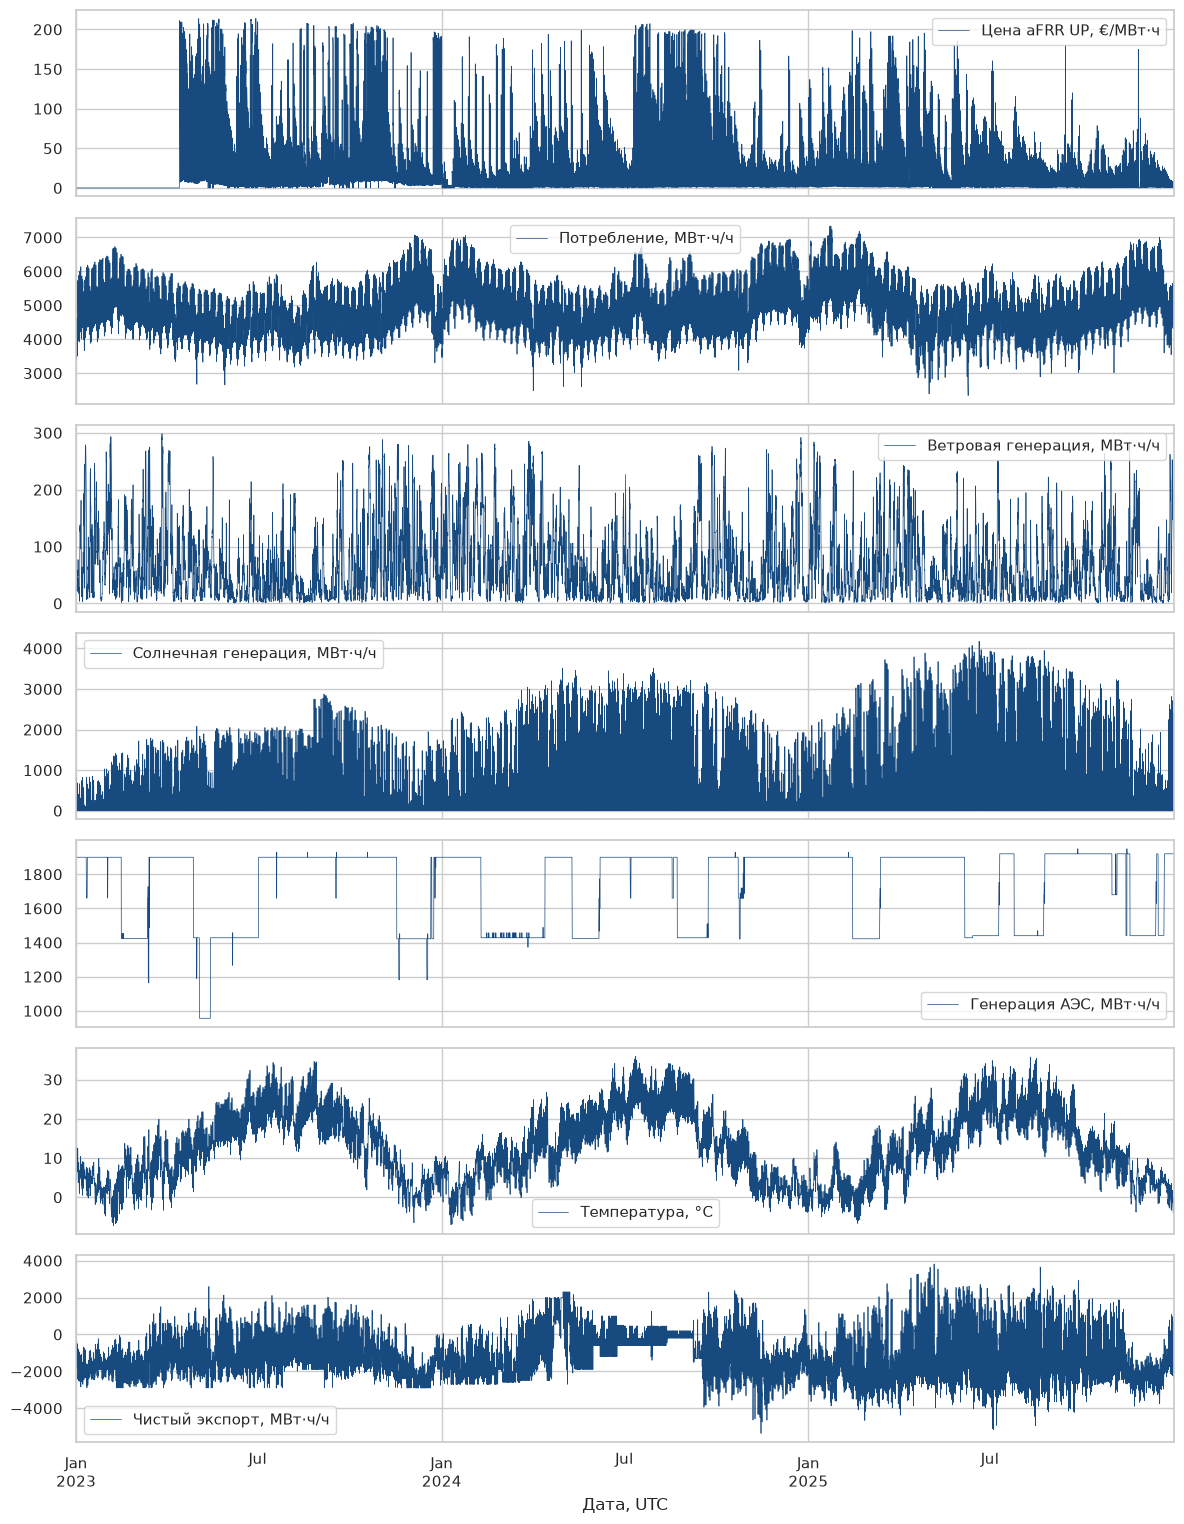

In [8]:
labels = {
    "target_vwap_up": "Цена aFRR UP, €/МВт·ч",
    "consumption": "Потребление, МВт·ч/ч",
    "wind": "Ветровая генерация, МВт·ч/ч",
    "solar": "Солнечная генерация, МВт·ч/ч",
    "nuclear": "Генерация АЭС, МВт·ч/ч",
    "temperature": "Температура, °C",
    "exchange_net_export": "Чистый экспорт, МВт·ч/ч",
    "carbon_intensity_production": "Углеродоёмкость, кг CO₂-экв./МВт·ч"
}
filled_columns = df[list(labels)].columns[df[list(labels)].notna().any()]
plot_data = df.set_index("datetime")[filled_columns]
plot_data = plot_data.rename(columns=labels)
plot_data.plot(subplots=True, sharex=True, figsize=(12, 2.2 * len(filled_columns)), linewidth=0.5, color="#174A7E")
plt.xlabel("Дата, UTC")
plt.tight_layout()
plt.show()

На графиках я сравнил начало и конец ряда, сезонные колебания, резкие изменения
и длительные участки на одном уровне. Отрицательные значения температуры и перетоков
сами по себе не являются ошибкой.

Чтобы дополнить визуальное впечатление числами, я вывел минимум, медиану и максимум факторов.
`describe()` считает основные статистики, а `.T` разворачивает таблицу для удобного чтения.

In [9]:
factors = list(filled_columns.drop("target_vwap_up"))
factor_summary = df[factors].describe().T
factor_summary = factor_summary[["min", "50%", "max"]]
factor_summary = factor_summary.rename(index=labels, columns={"min": "Минимум", "50%": "Медиана", "max": "Максимум"})
display(factor_summary)
print("Доля нулевой солнечной генерации, %:", round((df["solar"] == 0).mean() * 100, 2))

,Минимум,Медиана,Максимум
"Потребление, МВт·ч/ч","2,342.18","4,827.59","7,336.58"
"Ветровая генерация, МВт·ч/ч",0.55,48.04,298.60
"Солнечная генерация, МВт·ч/ч",0.00,30.09,"4,179.00"
"Генерация АЭС, МВт·ч/ч",956.00,"1,900.00","1,949.50"
"Температура, °C",-7.29,12.14,35.91
"Чистый экспорт, МВт·ч/ч","-5,365.30","-1,300.00","3,819.90"


Доля нулевой солнечной генерации, %: 44.71


Я использовал диапазоны для проверки масштаба каждого показателя.
Нулевая солнечная генерация ожидаема, в частности, ночью. У неё другой контекст,
чем у длительного нулевого начала цены. Диапазоны сами по себе не доказывают точность прогнозов.

## 4. Как распределена цена

Я сравнил среднее, медиану и 95-й процентиль. **Среднее** учитывает величину всех цен.
**Медиана** делит отсортированные наблюдения пополам.
**95-й процентиль** — уровень, который не превышают примерно 95% наблюдений.
Гистограмма показывает, сколько часов попало в каждый диапазон цены.

In [10]:
price_stats = price.describe(percentiles=[0.25, 0.5, 0.75, 0.95])
display(price_stats)
print("Отношение среднего к медиане:", round(price.mean() / price.median(), 2) if price.median() else "Медиана равна нулю")

count   26,304.00
mean        23.44
std         44.14
min          0.00
25%          1.02
50%          3.86
75%         21.75
95%        138.60
max        213.75
Name: target_vwap_up, dtype: float64

Отношение среднего к медиане: 6.07


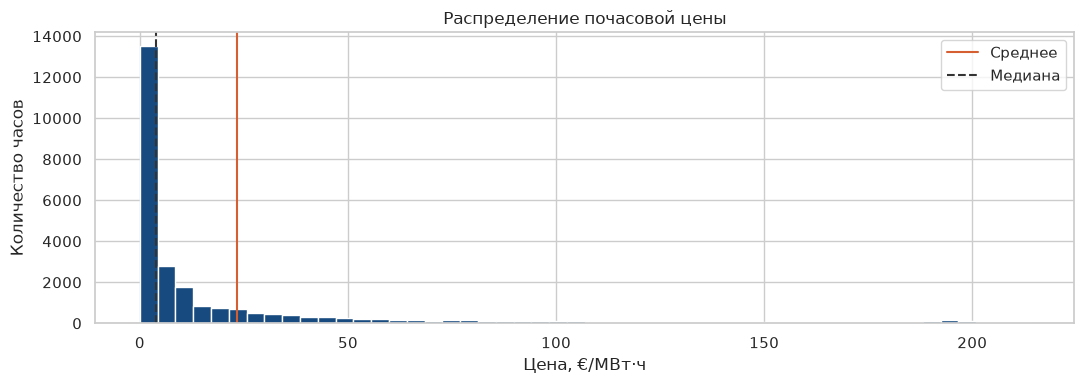

In [11]:
plt.hist(price, bins=50, color="#174A7E", edgecolor="white")
plt.axvline(price.mean(), color="#D65F32", label="Среднее")
plt.axvline(price.median(), color="#333333", linestyle="--", label="Медиана")
plt.title("Распределение почасовой цены")
plt.xlabel("Цена, €/МВт·ч")
plt.ylabel("Количество часов")
plt.legend()
plt.tight_layout()
plt.show()

Если среднее заметно выше медианы, дорогие часы поднимают его относительно середины распределения.
Поэтому для описания типичной цены я рассматриваю оба показателя.
Высокая цена сама по себе не доказывает ошибку: я сохранил её в анализе.

## 5. Как цена менялась со временем

Для годовой таблицы я использовал год **UTC**. `groupby` собирает строки одного года,
а `agg` считает для каждой группы количество, среднее и медиану.
Для графика я рассчитал средние цены по дням, чтобы общий ход ряда был заметнее.
Дневное значение — обычное среднее почасовых цен, а не новая средневзвешенная по объёму цена.

In [12]:
year = df["datetime"].dt.year
annual_price = df.groupby(year)["target_vwap_up"].agg(["count", "mean", "median"])
annual_price.columns = ["Часов", "Средняя цена", "Медиана"]
annual_price.index.name = "Год UTC"
annual_price

,Часов,Средняя цена,Медиана
Год UTC,,,
2023,8760,29.89,5.42
2024,8784,26.27,3.08
2025,8760,14.14,2.74


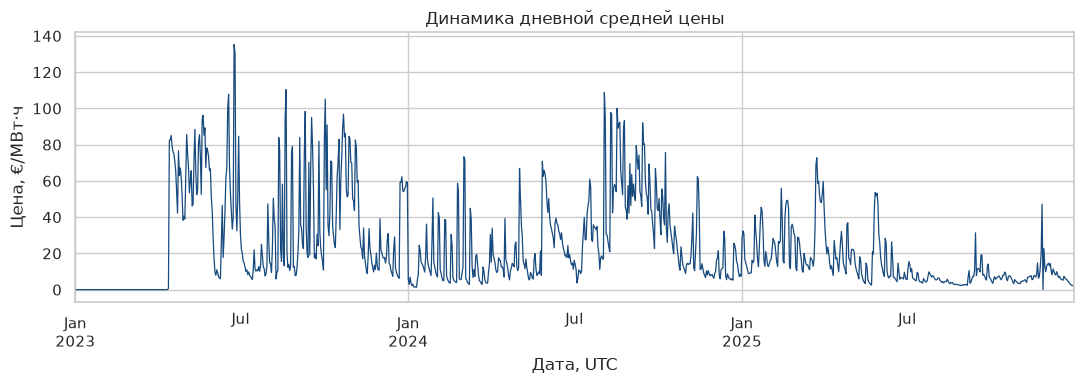

In [13]:
daily_price = df.set_index("datetime")["target_vwap_up"].resample("D").mean()
daily_price.plot(color="#174A7E", linewidth=0.9)
plt.title("Динамика дневной средней цены")
plt.xlabel("Дата, UTC")
plt.ylabel("Цена, €/МВт·ч")
plt.tight_layout()
plt.show()

Я сравнил средние и медианы между годами и посмотрел, совпадает ли это различие
с картиной на графике. Один общий показатель за три года может скрывать изменение уровня цены.
В полном високосном году 8 784 часа, в обычном — 8 760.
Годовые показатели включают начальный нулевой участок, если он есть в загруженной выборке.

## 6. Время суток и день недели

Я перевёл время в `Europe/Budapest`, чтобы сравнивать местное утро с утром,
а вечер с вечером. `tz_convert` учитывает переходы на летнее и зимнее время.
`dt.hour` выделяет час, `dt.dayofweek` — день недели (понедельник имеет номер 0).
Значения цены при этом не меняются.

Я сгруппировал все наблюдения по местному часу и сравнил среднее с медианой.
Годовые итоги выше остаются в UTC. На границе периода местная календарная дата
может относиться к следующему году; такой час тоже участвует в сравнении часов и дней недели.

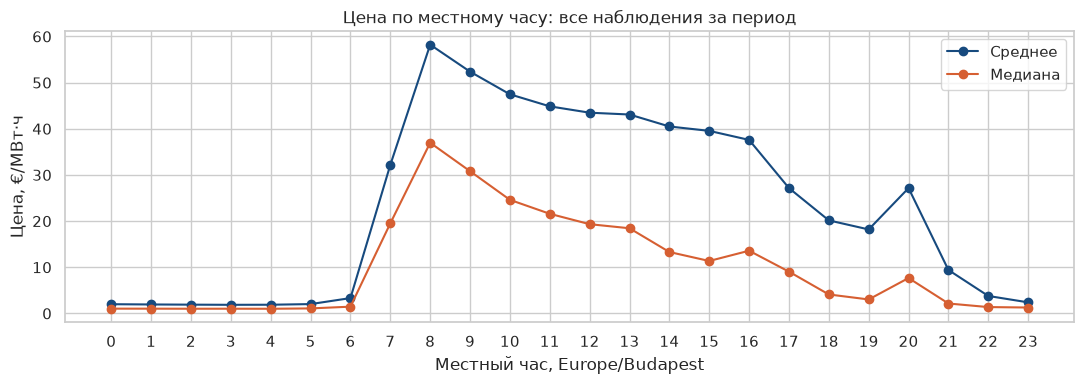

Среднее и медиана для 03:00 и 08:00:


,Среднее,Медиана
datetime,,
3,1.87,1.02
8,58.22,36.98


In [14]:
local_time = df["datetime"].dt.tz_convert("Europe/Budapest")
hour_price = df.groupby(local_time.dt.hour)["target_vwap_up"].agg(["mean", "median"])
hour_price.columns = ["Среднее", "Медиана"]
hour_price.plot(marker="o", color=["#174A7E", "#D65F32"])
plt.title("Цена по местному часу: все наблюдения за период")
plt.xlabel("Местный час, Europe/Budapest")
plt.ylabel("Цена, €/МВт·ч")
plt.xticks(range(24))
plt.tight_layout()
plt.show()
print("Среднее и медиана для 03:00 и 08:00:")
display(hour_price.reindex([3, 8]).round(2))

Я сравнил ночной и утренний часы по среднему и медиане.
Если различие видно по обоим показателям, оно не сводится только к отдельным очень дорогим часам.
Это объединённый профиль за весь период, а не обещание одинакового поведения в каждый день.

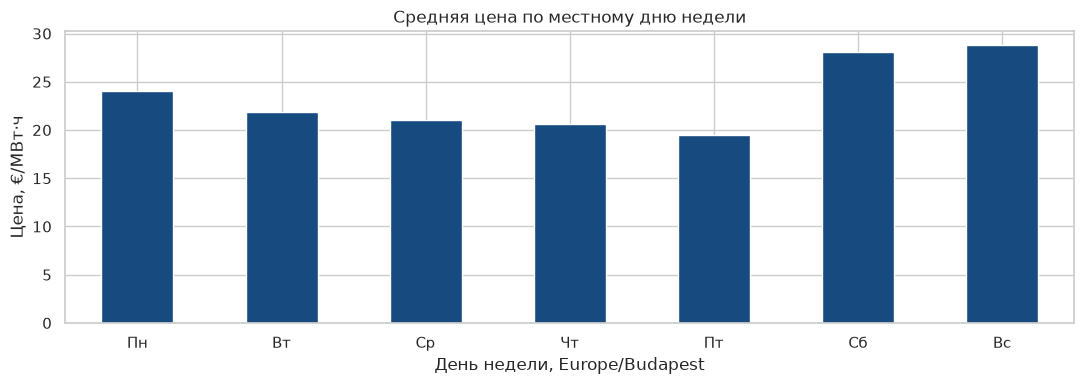

Средние цены по дням недели:


,"Средняя цена, €/МВт·ч"
Пн,24.09
Вт,21.89
Ср,21.06
Чт,20.62
Пт,19.49
Сб,28.10
Вс,28.82


In [15]:
weekday_price = df.groupby(local_time.dt.dayofweek)["target_vwap_up"].mean()
weekday_price = weekday_price.reindex(range(7))
weekday_price.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
weekday_price.plot(kind="bar", color="#174A7E", rot=0)
plt.title("Средняя цена по местному дню недели")
plt.xlabel("День недели, Europe/Budapest")
plt.ylabel("Цена, €/МВт·ч")
plt.tight_layout()
plt.show()
print("Средние цены по дням недели:")
display(weekday_price.round(2).to_frame("Средняя цена, €/МВт·ч"))

Различия средних по дням недели не означают, что один день всегда дороже другого.
На эти средние одновременно влияют сезон, год и дорогие эпизоды.

## 7. Простые связи с ценой

Я рассчитал **корреляцию Pearson**: она показывает направление и силу линейного совместного изменения.
Значение близко к +1 означает сильную связь в одном направлении, к −1 — в противоположных,
а около 0 — слабую линейную связь. Нулевая корреляция не исключает более сложную зависимость.

`corr()` строит таблицу коэффициентов. Я оставил её столбец с ценой и показал заполненные факторы.
Цветовая шкала фиксирована от −1 до +1, чтобы небольшие значения не выглядели сильной связью.

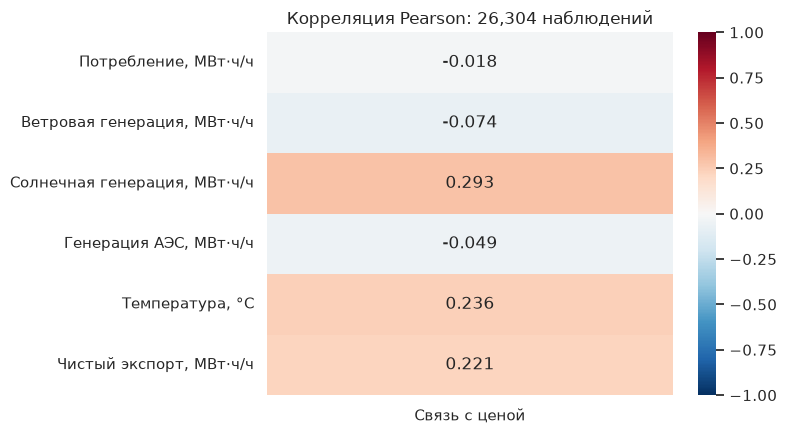

In [16]:
correlations = df[factors + ["target_vwap_up"]].corr()
price_correlations = correlations.loc[factors, ["target_vwap_up"]]
price_correlations = price_correlations.rename(index=labels, columns={"target_vwap_up": "Связь с ценой"})

plt.figure(figsize=(8, 4.5))
sns.heatmap(price_correlations, annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, center=0)
plt.title(f"Корреляция Pearson: {len(df):,} наблюдений")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

Корреляции описывают совместное изменение в загруженной выборке. Они **не доказывают причинность**
и не показывают качество будущего прогноза. Например, солнце и цена могут одновременно меняться
в течение суток. Начальный нулевой блок тоже входит в расчёт.
Поэтому я не стал отбирать или исключать признаки только по этой таблице.

## 8. Итоги EDA

Я проверил полноту временного ряда и столбцов, отдельно рассмотрел нулевое начало,
сравнил среднее с медианой, изучил динамику и календарные различия, затем оценил простые корреляции.
В таблице ниже я собрал основные числа из **текущей загрузки PostgreSQL**.
Их можно сопоставить с подробными таблицами и графиками выше.

In [17]:
summary = pd.Series({
    "Наблюдений": len(df),
    "Полностью пустых столбцов": int(df.isna().all().sum()),
    "Начальных нулевых часов": initial_zero_hours,
    "Доля нулей, %": (price == 0).mean() * 100,
    "Доля нулей после блока, %": (price_after_start == 0).mean() * 100,
    "Средняя цена, €/МВт·ч": price.mean(),
    "Медиана цены, €/МВт·ч": price.median(),
    "P95 цены, €/МВт·ч": price.quantile(0.95),
    "Максимальная цена, €/МВт·ч": price.max()
})
summary.round(2).to_frame("Результат")

,Результат
Наблюдений,"26,304.00"
Полностью пустых столбцов,1.00
Начальных нулевых часов,"2,470.00"
"Доля нулей, %",11.04
"Доля нулей после блока, %",1.82
"Средняя цена, €/МВт·ч",23.44
"Медиана цены, €/МВт·ч",3.86
"P95 цены, €/МВт·ч",138.60
"Максимальная цена, €/МВт·ч",213.75


Для следующего этапа я зафиксировал необходимость проверить календарные зависимости
и изменение цены во времени. Перед подготовкой данных к модели я уточнил бы происхождение
нулевых участков, экономический смысл целевой цены и время публикации факторов.
**Набор признаков и качество модели по одному EDA определить нельзя.**

Технические справки по загрузке: [pandas.read_sql_query](https://pandas.pydata.org/docs/reference/api/pandas.read_sql_query.html),
[SQLAlchemy URL.create](https://docs.sqlalchemy.org/en/20/core/engines.html#creating-urls-programmatically).